In [ ]:
import os
import numpy as np
import cv2
import matplotlib
from matplotlib import pyplot as plt
import pywt
import numpy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def getkey(dic,val):

  for key in dic:

    if dic[key]==val:
      return key


Ekta image  er path dile setar face crop kore cropped image return korbe

In [ ]:
def get_cropped_image(image_path): # ekta image  er path dile setar face crop kore cropped image return korbe
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.3, 5)
    for (x,y,w,h) in faces:
        roi_gray = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]
        eyes = eye_cascade.detectMultiScale(roi_gray)
        if len(eyes) >= 2:
            return roi_color

Wavelet Transform Function

In [ ]:
def w2d(img, mode='haar', level=1): #ekta image dile setake transorm kore dibe
    imArray = img
    #Datatype conversions
    #convert to grayscale
    imArray = cv2.cvtColor( imArray,cv2.COLOR_RGB2GRAY )
    #convert to float
    imArray =  np.float32(imArray)
    imArray /= 255;
    # compute coefficients
    coeffs=pywt.wavedec2(imArray, mode, level=level)

    #Process Coefficients
    coeffs_H=list(coeffs)
    coeffs_H[0] *= 0;

    # reconstruction
    imArray_H=pywt.waverec2(coeffs_H, mode);
    imArray_H *= 255;
    imArray_H =  np.uint8(imArray_H)

    return imArray_H

Initializing haarcascade

In [ ]:
#Finding the directory of the built in haar cascade xml file and storing the location in face_model
cv2_base_dir = os.path.dirname(os.path.abspath(cv2.__file__))
face_model= os.path.join(cv2_base_dir, 'data/haarcascade_frontalface_default.xml')
eye_model= os.path.join(cv2_base_dir, 'data/haarcascade_eye.xml')
face_cascade=cv2.CascadeClassifier(face_model) # building the classifier
eye_cascade=cv2.CascadeClassifier(eye_model)

*Cropped* folder


In [ ]:
path_data='/content/drive/MyDrive/CSE 422/project/Project/temp/Dataset'
path_cropped='/content/drive/MyDrive/CSE 422/project/Project/temp/Dataset/cropped'

In [ ]:
import shutil
if os.path.exists(path_cropped): # jodi folder age theke thake tahole delete kore abar banao
     shutil.rmtree(path_cropped)
os.mkdir(path_cropped)

Cropped folder er moddhe protijon er name e folder banacchi

In [ ]:

for entry in os.scandir(path_data): # entry te folder er dir obejct  return hobe.

    if entry.is_dir() and entry.name!='cropped':

      path_cropped_entry=path_cropped+'/'+entry.name
      path_entry=path_data+'/'+entry.name

      os.mkdir(path_cropped_entry) # cropped folder e protita celeb er name e folder banacchi

      count2=0

      for images_entry in os.scandir(path_entry):

        path_images_entry=images_entry.path

        #checking image ta jpg,png,/jpeg kina
        temp=images_entry.name.split('.')
        if temp[-1] in ['jpg','png','jpeg']:
          cropped_image_entry=get_cropped_image(path_images_entry)
          cropped_image_entry_path=path_cropped_entry+'/'+entry.name+str(count2)+'.png'

          if cropped_image_entry is not None:
            cv2.imwrite(cropped_image_entry_path,cropped_image_entry)
            count2+=1
          else:
            continue






Student Encode


In [ ]:
student_encoded={}
count1=0
for entry in os.scandir(path_data): # entry te folder er dir obejct  return hobe.

    if entry.is_dir() and entry.name!='cropped':
      student_encoded[entry.name]=count1
      count1+=1

X and Y setup

In [ ]:

x=[]
y=[]
for student in os.scandir(path_cropped): #student name

  for image in os.scandir(path_cropped+'/'+student.name): # images of that student
    y.append(student_encoded[student.name])
    temp=cv2.imread(image.path)

    temp=cv2.resize(temp, (120, 120))
    temp=temp.reshape(120*120*3,1)
    x.append(temp)




In [ ]:
# Do not run
x = np.array(x).reshape(len(x),120*120*3).astype(float)

Data normalizing (Not useful here. It is Decresing accuracy)

In [ ]:
# Do not run
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(x)
x = scaler.transform(x)

ValueError: ignored

X and y only grayscale

In [ ]:

x=[]
y=[]
for student in os.scandir(path_cropped): #student name

  for image in os.scandir(path_cropped+'/'+student.name): # images of that student
    y.append(student_encoded[student.name])
    temp=cv2.imread(image.path)
    temp=cv2.cvtColor(temp, cv2.COLOR_BGR2GRAY)
    temp=cv2.resize(temp, (120, 120))
    temp=temp.reshape(120*120,1)
    x.append(temp)



x = np.array(x).reshape(len(x),120*120).astype(float)





Only Wavelet

In [ ]:

x=[]
y=[]
for student in os.scandir(path_cropped): #student name

  for image in os.scandir(path_cropped+'/'+student.name): # images of that student
    y.append(student_encoded[student.name])
    temp=cv2.imread(image.path)
    temp = w2d(temp,'db1',5)
    temp=cv2.resize(temp, (120, 120))
    temp=temp.reshape(120*120,1)
    x.append(temp)



x = np.array(x).reshape(len(x),14400).astype(float)





X and Y setup with wavelet transform combined

In [ ]:

x=[]
y=[]
for student in os.scandir(path_cropped): #student name

  for image in os.scandir(path_cropped+'/'+student.name): # images of that student
        y.append(student_encoded[student.name])
        img = cv2.imread(image.path)
        scalled_raw_img = cv2.resize(img, (32, 32))
        img_har = w2d(img,'db1',5)
        scalled_img_har = cv2.resize(img_har, (32, 32))
        combined_img = np.vstack((scalled_raw_img.reshape(32*32*3,1),scalled_img_har.reshape(32*32,1)))
        x.append(combined_img)

x = np.array(x).reshape(len(x),4096).astype(float)

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

x,y train test split


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y,train_size=.9,random_state=0)

X,y manual train test split(Colored)

In [ ]:

x_train=[]
x_test=[]
y_train=[]
y_test=[]
for student in os.scandir(path_cropped): #student name
  count=1
  for image in os.scandir(path_cropped+'/'+student.name): # images of that student

    if count%10==0: #5 tar moddhe 4 ta train e ar ekta test e.
      y_test.append(student_encoded[student.name])
      temp=cv2.imread(image.path)

      temp=cv2.resize(temp, (120, 120))
      temp=temp.reshape(120*120*3,1)
      x_test.append(temp)
    else:

      y_train.append(student_encoded[student.name])
      temp=cv2.imread(image.path)

      temp=cv2.resize(temp, (120, 120))
      temp=temp.reshape(120*120*3,1)
      x_train.append(temp)

    count+=1



x_train = np.array(x_train).reshape(len(x_train),14400*3).astype(float)
x_test = np.array(x_test).reshape(len(x_test),14400*3).astype(float)





SVC (Sigmoid) with Pipeline


In [ ]:

pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel = 'sigmoid'))])
pipe.fit(x_train, y_train)
print("Training accuracy of the model is {:.2f}".format(pipe.score(x_train, y_train)))   # traning accuracy percentage ashbe
print("Testing accuracy of the model is {:.2f}".format(pipe.score(x_test, y_test)))      # testing accurace pe

Training accuracy of the model is 0.57
Testing accuracy of the model is 0.51


SVM (RBF)

In [ ]:


svcr=SVC(kernel='rbf')
svcr.fit(x_train,y_train)
svcr.score(x_test, y_test)

print("Training accuracy of the model is {:.2f}".format(svcr.score(x_train, y_train)))   # traning accuracy percentage ashbe
print("Testing accuracy of the model is {:.2f}".format(svcr.score(x_test, y_test)))      # testing accurace perc

Training accuracy of the model is 0.90
Testing accuracy of the model is 0.76


Svm (Linear)


In [ ]:
svc=SVC(kernel='linear')
svc.fit(x_train,y_train)
svc.score(x_test, y_test)

print("Training accuracy of the model is {:.2f}".format(svc.score(x_train, y_train)))   # traning accuracy percentage ashbe
print("Testing accuracy of the model is {:.2f}".format(svc.score(x_test, y_test)))      # testing accurace percentage ashbe

Training accuracy of the model is 1.00
Testing accuracy of the model is 0.92


Random Forest

In [ ]:

from sklearn.ensemble import RandomForestClassifier

rfc=RandomForestClassifier(n_estimators=50)  # ekhane n_estimators er value 1000 dile rfc score er value beshi ashe (Mufrad)
rfc.fit(x_train,y_train)
rfc.score(x_test, y_test)

print("Training accuracy of the model is {:.2f}".format(rfc.score(x_train, y_train)))
print("Testing accuracy of the model is {:.2f}".format(rfc.score(x_test, y_test)))

Training accuracy of the model is 1.00
Testing accuracy of the model is 0.83


Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
gnb=GaussianNB()
gnb.fit(x_train,y_train)
gnb.score(x_test, y_test)

print("Training accuracy of the model is {:.2f}".format(gnb.score(x_train, y_train)))
print("Testing accuracy of the model is {:.2f}".format(gnb.score(x_test, y_test)))

Training accuracy of the model is 0.35
Testing accuracy of the model is 0.29


Neural network

In [ ]:
from sklearn.neural_network import MLPClassifier
nnc=MLPClassifier(hidden_layer_sizes=(7),activation='relu',max_iter=10000)
nnc.fit(x_train,y_train)
nnc.score(x_test, y_test)
nnc.score(x_train, y_train)

print("Training accuracy of the model is {:.2f}".format(nnc.score(x_train, y_train)))
print("Testing accuracy of the model is {:.2f}".format(nnc.score(x_test, y_test)))

Training accuracy of the model is 0.06
Testing accuracy of the model is 0.07


Group Image testing

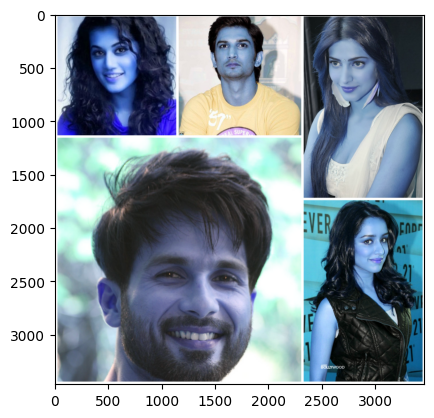

In [ ]:
img = cv2.imread('/content/drive/MyDrive/CSE 422/project/Group image/Group_pic_1.jpg')
#img = cv2.imread('/content/drive/MyDrive/CSE 422/project/Group image/Group_pic_2.png')
plt.imshow(img)

Prediction Using Support vector machine

In [ ]:
res=[]

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.3, 5)
for (x,y,w,h) in faces: # img te jotogula face ache protitar jonno loop
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w] # face crop kortesi
    temp=roi_color

    #Array format e antesi
    temp=cv2.resize(temp, (120, 120))
    temp=temp.reshape(120*120*3,1)
    t=[]
    t.append(temp)
    temp=t
    temp = np.array(temp).reshape(len(temp),120*120*3).astype(float)

    #predicting and saving in res
    temp=svc.predict(temp)
    res.append(temp)


print("People present are:")
for x in res:
  print(getkey(student_encoded,x[0]))  #res er value gular corresponding name print kortesi.




NameError: ignored

Prediction using Naive Bayes

In [ ]:
res=[]

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.3, 5)
for (x,y,w,h) in faces: # img te jotogula face ache protitar jonno loop
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w] # face crop kortesi
    temp=roi_color

    #Array format e antesi
    temp=cv2.resize(temp, (120, 120))
    temp=temp.reshape(120*120*3,1)
    t=[]
    t.append(temp)
    temp=t
    temp = np.array(temp).reshape(len(temp),120*120*3).astype(float)

    #predicting and saving in res
    temp=gnb.predict(temp)
    res.append(temp)


print("People present are:")
for x in res:
  print(getkey(student_encoded,x[0]))  #res er value gular corresponding name print kortesi.

People present are:
Varun_Dhawan
Shruti_Haasan
Sonam_Kapoor
Tabu
Zareen_Khan
Tamannaah_Bhatia
